# Peyrache Lab: Raw and Processed Data

This notebook reads one combined file for A0662 2022-11-14: the published DANDI:001676 asset for the session, with the raw data from this conversion added to it (append mode). The published file is only read; the combined file is a new file.

## What the raw conversion adds

| Where in the file | What it is | Not in the published file because |
|---|---|---|
| `acquisition/OnePhotonSeries` | The raw Miniscope V4 video: 35,785 frames of 608 × 608 pixels, each timed at its Intan frame-gate transition | The published file has only ROI traces and masks, starting at raw frame 34 |
| `acquisition/TimeSeriesIntanSync` | The two Intan ADC sync channels, Miniscope frame gate and OptiTrack sync, as recorded (20 kHz) | Not published |
| `events/MiniscopeFrameGate` | Every transition of the frame gate, one per Miniscope frame | Not published |
| `events/OptiTrackSync` | Every rising edge of the OptiTrack sync, one per OptiTrack frame, including those sent while Motive was not recording | Not published |
| `processing/behavior/PositionRigidBody` | The raw OptiTrack take position: X, Y and Z for all 144,240 take frames | The published `2D_position` has only X and Z (no height), cut at the last imaging frame (144,041 samples) |
| `processing/behavior/OrientationRigidBody` | The raw take orientation: all three rotation angles, in degrees | The published `head-direction` has only the yaw (Rotation Y), in radians |

## What the raw conversion changes

- The imaging plane and Miniscope device are this conversion's (Postsubiculum, stereotaxic coordinates, Miniscope V4). The published plane segmentation is relinked to that plane.
- `session_start_time` is the Intan recording start, the clock all timestamps are on. File-level and subject metadata are this conversion's, except `Subject.age`, which keeps its published value. The published session and experiment descriptions are appended to this conversion's.
- The published `2D_position` and `head-direction` keep their data and timestamps. Their descriptions now name the raw series they come from, and the position unit `m` becomes `meters`.

## What is carried over unchanged

The published ΔF/F (`DfOverF`), fluorescence, ROI masks (`ImageSegmentation`), tuning curves, `miniscope_FOV`, `2D_position` and `head-direction`, values and timestamps.

## How the raw data is timed

The raw frames and the raw take are timed with the lab's own detection rule (loadCalciumData in gviejo/PSBImaging): raw frame i is frame-gate transition i, and take frame i is OptiTrack sync pulse i. So the raw frames the published traces cover carry exactly the published ROI timestamps, and the raw take carries exactly the published behavior timestamps; sections 3, 6 and 7 check this. This session has no frames dropped from the video.

## 1. Setup

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from pynwb import read_nwb

nwb_path = "/Users/weian/nwb_output/peyrache/sub-A0662_ses-2022-11-14_behavior+ophys.nwb"
nwbfile = read_nwb(nwb_path)

## 2. What the file contains

The session and experiment descriptions describe the combined file and end with the published descriptions verbatim, which carry the environment, the session's position in its cell-registration phase ("session k of N") and the phase protocol. The start time, imaging-plane coordinates and device come from the conversion.

In [3]:
print(f"session_id           : {nwbfile.session_id}")
print(f"session_start_time   : {nwbfile.session_start_time}  (Intan recording start)")
print("session_description:")
print(nwbfile.session_description)
print()
print("experiment_description:")
print(nwbfile.experiment_description)
print()
print(f"subject              : {nwbfile.subject.subject_id}, age {nwbfile.subject.age}")
print()
print("acquisition :", sorted(nwbfile.acquisition))
print("processing  :", {name: sorted(module.data_interfaces) for name, module in nwbfile.processing.items()})
print("events      :", sorted(nwbfile.events))

plane = nwbfile.imaging_planes["ImagingPlane"]
print()
print(f"ImagingPlane location : {plane.location}")
print(f"origin_coords         : {plane.origin_coords[:]} {plane.origin_coords_unit}")
print(f"reference_frame       : {plane.reference_frame}")
print(f"device                : {plane.device.name} ({type(plane.device).__name__}), model {plane.device.model.name}")

session_id           : 2022-11-14
session_start_time   : 2022-11-14 10:14:44-04:00  (Intan recording start)
session_description:
Raw one-photon calcium imaging (UCLA Miniscope V4) from the Postsubiculum of a freely moving mouse during a longitudinal head-direction cell recording. The raw data includes the Miniscope video, the Intan synchronisation channels and the Miniscope frame-gate transitions as events. The processed data includes DF/F traces, ROI footprints, CellReg registration, and the 2D position and head direction from OptiTrack.

Session: Freely-moving exploration, environment: Open field, session 12 of 15

experiment_description:
Longitudinal recording of GCaMP6f-expressing cells in the PostSubiculum of freely-moving C57BL/6J mice using a UCLA Miniscope V4 one-photon fluorescence microscope. Mice explored different environments over several months to characterise the long-term stability of head-direction cell representations. Behavioural position and head orientation were tr

## 3. Raw frames and ROI traces

The published traces start at the first OptiTrack pulse, so they begin at a later raw frame. From there on every ROI sample carries the time of a raw frame, so a trace sample and the raw frame it was extracted from are found by index.

In [4]:
ops = nwbfile.acquisition["OnePhotonSeries"]
dff = nwbfile.processing["ophys"]["DfOverF"]["ROI_dFF"]

frame_times = ops.timestamps[:]
roi_times = dff.timestamps[:]

first_frame = int(np.searchsorted(frame_times, roi_times[0]))
shared = frame_times[first_frame:first_frame + len(roi_times)]

print(f"raw frames            : {len(frame_times):,}  ({frame_times[0]:.4f} – {frame_times[-1]:.4f} s)")
print(f"ROI samples           : {len(roi_times):,}  ({roi_times[0]:.4f} – {roi_times[-1]:.4f} s)")
print(f"first ROI sample      : raw frame {first_frame}")
print(f"timestamps identical  : {np.array_equal(shared, roi_times)}")
print()
print("OnePhotonSeries description:")
print(ops.description)

raw frames            : 35,785  (1.5922 – 1202.9880 s)
ROI samples           : 35,751  (2.7338 – 1202.9880 s)
first ROI sample      : raw frame 34
timestamps identical  : True

OnePhotonSeries description:
Raw calcium imaging video from a UCLA Miniscope V4 one-photon fluorescence microscope. The timestamps are derived from the Intan hardware sync channel (Miniscope frame-gate square wave).



## 4. Raw frames

A few frames of the raw Miniscope video, spread over the session.

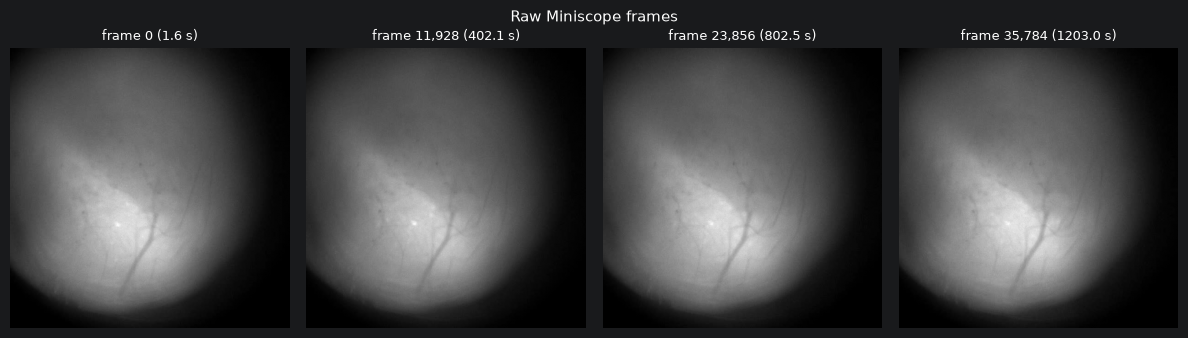

In [5]:
frame_ids = np.linspace(0, len(frame_times) - 1, 4).astype(int)
fig, axes = plt.subplots(1, 4, sharex=True, sharey=True, figsize=(12, 3.4), dpi=100)
for ax, i in zip(axes, frame_ids):
    ax.imshow(ops.data[i], cmap="gray")
    ax.set_title(f"frame {i:,} ({frame_times[i]:.1f} s)", fontsize=9)
    ax.axis("off")
plt.suptitle("Raw Miniscope frames", fontsize=11)
plt.tight_layout()
plt.show()

## 5. ΔF/F traces


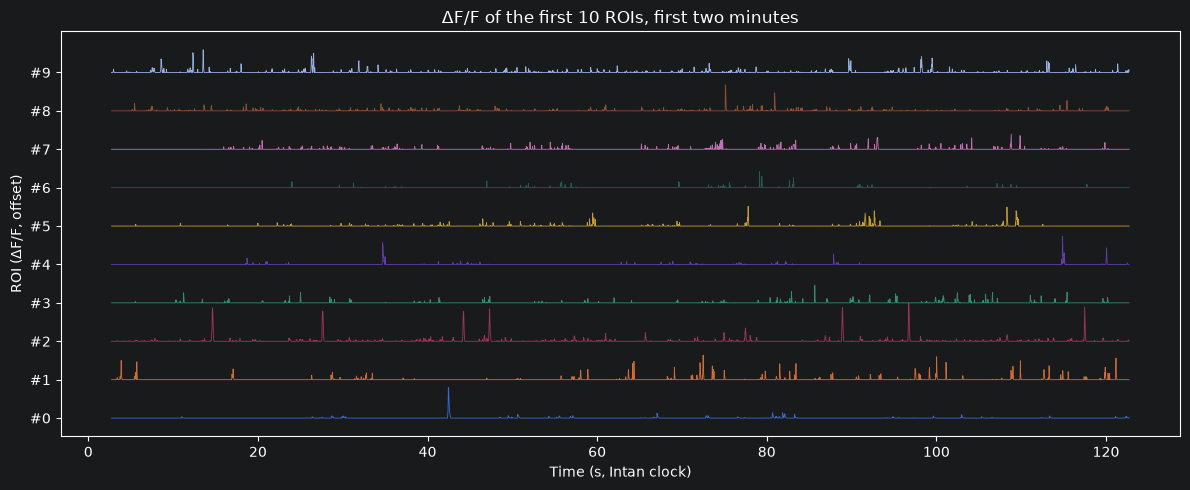

In [6]:
roi_ids = range(10)
dff_data = dff.data[:]
window = roi_times < roi_times[0] + 120  # first two minutes
offset = np.nanmax(dff_data[window][:, list(roi_ids)])  # one trace height
fig, ax = plt.subplots(figsize=(12, 5), dpi=100)
for k, roi_id in enumerate(roi_ids):
    ax.plot(roi_times[window], dff_data[window, roi_id] + offset * k, lw=0.6)
ax.set_yticks([offset * k for k in range(len(roi_ids))], [f"#{r}" for r in roi_ids])
ax.set_xlabel("Time (s, Intan clock)")
ax.set_ylabel("ROI (ΔF/F, offset)")
ax.set_title("ΔF/F of the first 10 ROIs, first two minutes")
plt.tight_layout()
plt.show()

## 6. Frame-gate events

`MiniscopeFrameGate` holds every transition of the Intan frame gate. Each transition is one Miniscope frame, so raw frame i is row i of this table. In this session the gate has exactly one transition per frame. In some sessions it keeps toggling for a few frames after the video stops, and the table then has a few more rows than there are frames.

In [7]:
gate = nwbfile.events["MiniscopeFrameGate"]
gate_times = gate["timestamp"][:]
print(f"transitions                : {len(gate_times):,}")
print(f"raw frames                 : {len(frame_times):,}")
print(f"frame i is transition i    : {np.array_equal(gate_times[:len(frame_times)], frame_times)}")

transitions                : 35,785
raw frames                 : 35,785
frame i is transition i    : True


## 7. Raw OptiTrack take and published behavior

The raw take holds all three position axes and all three rotation angles for every OptiTrack frame. Take frame i is OptiTrack sync pulse i on the Intan clock (`OptiTrackSync`). The published `2D_position` is Position X and Z of the take, and `head-direction` is its Rotation Y in radians, both cropped to the last imaging frame.


In [8]:
behavior = nwbfile.processing["behavior"]
take_position = behavior["PositionRigidBody"]
take_orientation = behavior["OrientationRigidBody"]
published_position = nwbfile.acquisition["Position"]["2D_position"]
published_head_direction = nwbfile.acquisition["head-direction"]

n = len(published_position.timestamps)
take_times = take_position.timestamps[:]
xyz = take_position.data[:]
yaw = np.mod(np.deg2rad(take_orientation.data[:n, 1]), 2 * np.pi)
tracked = ~np.isnan(xyz[:n]).any(axis=1)

print(f"take frames                : {len(take_times):,}  ({take_times[0]:.4f} – {take_times[-1]:.4f} s)")
print(f"published samples          : {n:,}")
print(f"timestamps identical       : {np.array_equal(take_times[:n], published_position.timestamps[:])}")
print(f"position X, Z identical    : {np.array_equal(xyz[:n][tracked][:, [0, 2]], published_position.data[:][tracked])}")
print(f"head direction max diff    : {np.max(np.abs(yaw[tracked] - published_head_direction.data[:][tracked])):.1e} rad")
print(f"sync pulses (OptiTrackSync): {len(nwbfile.events['OptiTrackSync']['timestamp'][:]):,}")
print()
print("OrientationRigidBody description:")
print(take_orientation.description)


take frames                : 144,240  (2.7055 – 1204.6409 s)
published samples          : 144,041
timestamps identical       : True
position X, Z identical    : True
head direction max diff    : 8.9e-16 rad
sync pulses (OptiTrackSync): 144,629

OrientationRigidBody description:
Orientation of Rigid Body 'RigidBody' as intrinsic Euler angles in degrees (x, y, z), applied in Motive's YXZ rotation order, relative to the room axes, with zero at its pose when it was created (or last reset) in Motive.


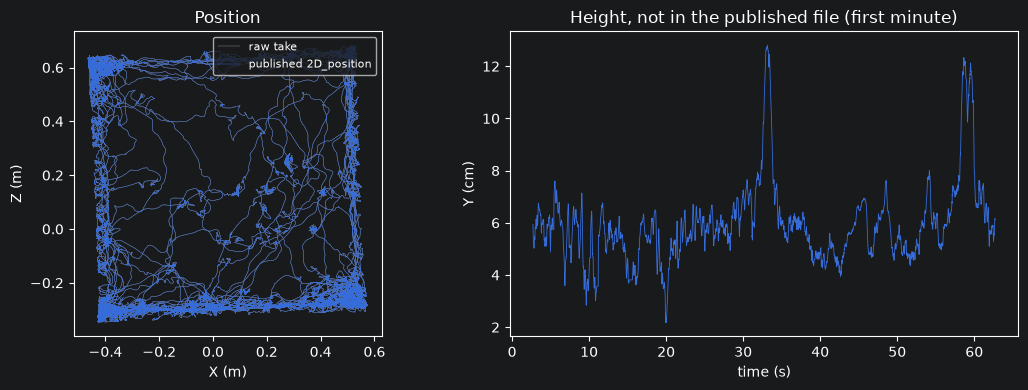

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(xyz[:, 0], xyz[:, 2], lw=0.3, color="0.6", label="raw take")
axes[0].plot(*published_position.data[:].T, lw=0.3, color="C0", label="published 2D_position")
axes[0].set(xlabel="X (m)", ylabel="Z (m)", aspect="equal", title="Position")
axes[0].legend(loc="upper right", fontsize=8)
window = slice(0, 120 * 60)
axes[1].plot(take_times[window], xyz[window, 1] * 100, lw=0.6)
axes[1].set(xlabel="time (s)", ylabel="Y (cm)", title="Height, not in the published file (first minute)")
plt.tight_layout()
plt.show()


In [10]:
nwbfile.read_io.close()